In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
from allensdk.core.mouse_connectivity_cache import MouseConnectivityCache
import matplotlib.pyplot as plt
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *

In [3]:
prefix = '/mnt/staging/'
figure_config_root = str(PREPARES / "config") + "/"
palatte_dict = load_pickle(figure_config_root+'palatte_dict')

In [4]:
from pathlib import Path


In [5]:
def save_dict_to_hdf5(dic, filename):
    with h5py.File(filename, 'w') as h5file:
        recursively_save_dict_contents_to_group(h5file, '/', dic)

def recursively_save_dict_contents_to_group(h5file, path, dic):
    for key, item in dic.items():
        if isinstance(item, (np.ndarray, np.int64, np.float64, np.int32, np.float32)):
            h5file.create_dataset(path + key, data=item, compression='gzip')
        elif isinstance(item, str):
            dt = h5py.string_dtype(encoding='utf-8')
            h5file.create_dataset(path + key, data=item, dtype=dt)
        elif isinstance(item, dict):
            recursively_save_dict_contents_to_group(h5file, path + key + '/', item)
        else:
            raise ValueError('Cannot save %s type' % type(item))

In [13]:
from allensdk.core.mouse_connectivity_cache import MouseConnectivityCache

# The manifest file is a simple JSON file that keeps track of all of
# the data that has already been downloaded onto the hard drives.
# If you supply a relative path, it is assumed to be relative to your
# current working directory.
result_path = str(PREPARES / "allen-connectivity-atlas/NEW/wild-type-S1")
output_dir = result_path
mcc = MouseConnectivityCache(manifest_file=Path(output_dir) / 'manifest.json',resolution=10)

# open up a list of all of the experiments
all_experiments = mcc.get_experiments(dataframe=True)
print("%d total experiments" % len(all_experiments))

# take a look at what we know about an experiment with a primary motor injection
all_experiments.loc[181819064]

2992 total experiments


gender                                                         F
injection_structures                                       [345]
injection_volume                                        0.303349
injection_x                                                 4700
injection_y                                                 2680
injection_z                                                 9270
product_id                                                     5
specimen_name                                Scnn1a-Tg3-Cre-4827
strain                                                    B6.C3H
structure_abbrev                                           SSp-m
structure_id                                                 345
structure_name                 Primary somatosensory area, mouth
transgenic_line                                   Scnn1a-Tg3-Cre
transgenic_line_id                                   177837516.0
id                                                     181819064
primary_injection_structu

In [18]:
S1_experiment_ids = {
    "VISp": 307558646,
    "SSp-m": 114290938, #wild type
    # "SSp-m":181819064, # Scnn1a-Tg3-Cre
    "SSp-n": 112162251,
    # "SSp-ul": 112229814, #wild type
    "SSp-ul":286312782, #Rbp4-Cre_KL100
    "SSp-ll": 112935169,
    "SSp-bfd": 127866392
}

In [15]:
dict_pd = {}
dict_pd_info = {}
dict_ind = {}
dict_ind_info = {}
for key in S1_experiment_ids:
    experiment_id = S1_experiment_ids[key]
    # projection density: number of projecting pixels / voxel volume
    pd, pd_info = mcc.get_projection_density(experiment_id)
    dict_pd[key]=pd
    dict_pd_info[key]=pd_info
    
    # injection density: number of projecting pixels in injection site / voxel volume
    ind, ind_info = mcc.get_injection_density(experiment_id) 
    dict_ind[key] = ind
    dict_ind_info[key] = ind_info
    

2025-07-17 14:19:43,351 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/181819064?image=projection_density&resolution=10
2025-07-17 14:20:21,988 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/181819064?image=injection_density&resolution=10


In [16]:
for key in dict_pd.keys():
    print(dict_pd[key].shape)

(1320, 800, 1140)
(1320, 800, 1140)
(1320, 800, 1140)
(1320, 800, 1140)
(1320, 800, 1140)
(1320, 800, 1140)


In [17]:
from save_dict_to_hdf5 import *
save_dict_to_hdf5(dict_pd,result_path+'/wild_type_S1.h5')

# M2

In [17]:
result_path = str(PREPARES / "allen-connectivity-atlas/NEW/wild-type-M2")

need to see coordinates

In [18]:
MOs,info = mcc.get_structure_mask(993)

2025-07-08 13:08:45,285 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://download.alleninstitute.org/informatics-archive/current-release/mouse_ccf/annotation/ccf_2017/structure_masks/structure_masks_10/structure_993.nrrd


In [27]:
results_coord={}
results_coord['HP'] = (290,610)
results_coord['FP'] = (237,700)
results_coord['mouth']=(356, 820)
results_coord['nose']=(360, 740)
results_coord['whisker'] = (394, 656.989247311828)
results_coord['visual'] = (506, 605.939393939394)
bodyparts = results_coord.keys()
bdp_short_dict_2 = {"whisker":'RW', "mouth":'RM', "nose":'RN', "FP":'RFP', "HP":'RHP',
                    "visual":'RV'}

In [43]:
experiment_ids_MOs = {
    "MOs_whisker": 141603190,
    "MOs_FP": 157710335,
    # "MOs_HP": 112952510,
    "MOs_nose": 585025284,
    "MOs_HP": 100141454,

}

In [20]:
# Get ALL experiments as DataFrame
all_experiments = mcc.get_experiments(dataframe=True)
print(f"{len(all_experiments)} total experiments")

2992 total experiments


Found 4 experiments.


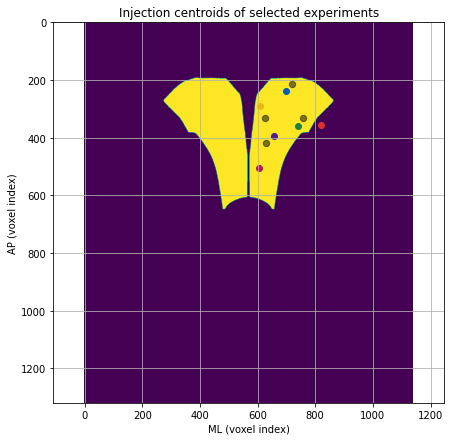

In [44]:
import matplotlib.pyplot as plt

# Your list of experiment IDs
experiment_ids = experiment_ids_MOs.values()

# Filter DataFrame to only these experiments
selected_experiments = all_experiments.loc[experiment_ids]

# Confirm they are all found
print(f"Found {len(selected_experiments)} experiments.")

# Extract coordinates
ap_um = selected_experiments["injection_x"].values
ml_um = selected_experiments["injection_z"].values

# Convert µm to voxel indices in your MIP matrix (voxel size = 10um)
ap_voxels = ap_um / 10
ml_voxels = ml_um / 10

# Plot
plt.figure(figsize=(7,7))

# Optional: background (e.g., MIP of your mask)
# plt.imshow(MIP_surface, cmap="gray", alpha=0.3)
# plt.imshow(results_blob[bdp]==1)
plt.imshow(np.squeeze(np.max(MOs,1)))
plt.scatter(ml_voxels, ap_voxels, c='black', s=40, edgecolors='k',alpha=0.5)
for bdp in bodyparts:
    plt.scatter(results_coord[bdp][1],results_coord[bdp][0],c=palatte_dict[bdp_short_dict_2[bdp]])

# plt.gca().invert_yaxis()  # So anterior is top
plt.xlabel("ML (voxel index)")
plt.ylabel("AP (voxel index)")
plt.title("Injection centroids of selected experiments")
plt.grid(True)
plt.axis("equal")
plt.show()


In [47]:
result_path = str(PREPARES / "allen-connectivity-atlas/NEW/wild-type-M2")
output_dir = result_path
mcc = MouseConnectivityCache(manifest_file=Path(output_dir) / 'manifest.json',resolution=10)

# open up a list of all of the experiments
all_experiments = mcc.get_experiments(dataframe=True)
print("%d total experiments" % len(all_experiments))

2992 total experiments


In [48]:
dict_pd = {}
dict_pd_info = {}
dict_ind = {}
dict_ind_info = {}
for key in experiment_ids_MOs:
    experiment_id = experiment_ids_MOs[key]
    # projection density: number of projecting pixels / voxel volume
    pd, pd_info = mcc.get_projection_density(experiment_id)
    dict_pd[key]=pd
    dict_pd_info[key]=pd_info
    
    # injection density: number of projecting pixels in injection site / voxel volume
    ind, ind_info = mcc.get_injection_density(experiment_id) 
    dict_ind[key] = ind
    dict_ind_info[key] = ind_info
    

2025-07-08 13:58:33,810 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/141603190?image=projection_density&resolution=10
2025-07-08 13:59:45,970 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/141603190?image=injection_density&resolution=10
2025-07-08 14:00:08,839 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/157710335?image=projection_density&resolution=10
2025-07-08 14:01:09,283 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/157710335?image=injection_density&resolution=10
2025-07-08 14:01:31,405 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/585025284?image=projection_density&resolution=10
2025-07-08 14:02:19,250 allensdk.api.api.retrieve_file_ov

In [49]:
for key in dict_pd.keys():
    print(dict_pd[key].shape)

(1320, 800, 1140)
(1320, 800, 1140)
(1320, 800, 1140)
(1320, 800, 1140)


In [50]:
from save_dict_to_hdf5 import *
save_dict_to_hdf5(dict_pd,result_path+'/wild_type_M2.mat')

2992 total experiments


# M2 but not wild type

In [52]:
dict_experiment_ids_M2_extra = {
                      'MOs_mouth':166082128, #Rbp4-Cre-113
                      'MOs_visual':158018630 #Gng7-Cre-971
}



In [54]:
result_path = str(PREPARES / "allen-connectivity-atlas/NEW/extra-M2")
output_dir = result_path
mcc = MouseConnectivityCache(manifest_file=Path(output_dir) / 'manifest.json',resolution=10)

# open up a list of all of the experiments
all_experiments = mcc.get_experiments(dataframe=True)
print("%d total experiments" % len(all_experiments))

2992 total experiments


In [55]:
dict_pd = {}
dict_pd_info = {}
dict_ind = {}
dict_ind_info = {}
for key in dict_experiment_ids_M2_extra:
    experiment_id = dict_experiment_ids_M2_extra[key]
    # projection density: number of projecting pixels / voxel volume
    pd, pd_info = mcc.get_projection_density(experiment_id)
    dict_pd[key]=pd
    dict_pd_info[key]=pd_info
    
    # injection density: number of projecting pixels in injection site / voxel volume
    ind, ind_info = mcc.get_injection_density(experiment_id) 
    dict_ind[key] = ind
    dict_ind_info[key] = ind_info
    

2025-07-08 14:27:17,816 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/166082128?image=projection_density&resolution=10
2025-07-08 14:28:20,212 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/166082128?image=injection_density&resolution=10
2025-07-08 14:28:41,194 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/158018630?image=projection_density&resolution=10
2025-07-08 14:29:27,507 allensdk.api.api.retrieve_file_over_http INFO     Downloading URL: http://api.brain-map.org/grid_data/download_file/158018630?image=injection_density&resolution=10


In [56]:
from save_dict_to_hdf5 import *
save_dict_to_hdf5(dict_pd,result_path+'/other_types_M2.mat')

In [58]:
import scipy
scipy.io.savemat('other_types_M2.mat', dict_pd, format='7.3')

ValueError: Format should be '4' or '5'

# END HERE

(1200.0, 180.0)

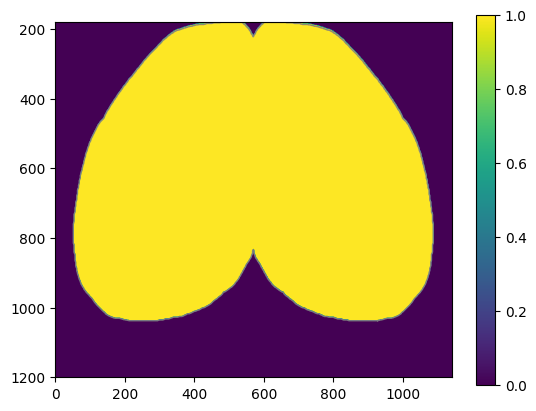

In [26]:
# in addition to the annotation volume, you can get binary masks for individual structures
# in this case, we'll get one for the isocortex
cortex_mask, cm_info = mcc.get_structure_mask(315)

cortex_mask_mip = cortex_mask.max(axis=1)

from skimage import measure
brain_contours = measure.find_contours(cortex_mask_mip>0.5, level=0.5)

    
plt.imshow(cortex_mask_mip)
plt.colorbar()
for contour in brain_contours:
    plt.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=0.9)
# plt.xlim([20,436])
plt.ylim([1200,160])

In [14]:
cortex_mask_mip.shape

(1320, 1140)

In [15]:
dict_coord={}
dict_S1_contour = {}
from scipy.ndimage import center_of_mass
for key in dict_experiment_id:
    dict_coord[key] = center_of_mass(dict_ind[key].max(axis=1))
    S1_contours = measure.find_contours(dict_ind[key].max(axis=1)>0.5, level=0.5)
    dict_S1_contour[key] = S1_contours

In [17]:
from matplotlib.colors import LinearSegmentedColormap
# def make_custom_cmap(hex_color, name):
#     return LinearSegmentedColormap.from_list(name, ['black', hex_color])


from matplotlib.colors import LinearSegmentedColormap, to_rgb

def make_dynamic_cmap(hex_color, name):
    base_rgb = to_rgb(hex_color)
    
    # Add a middle point (scaled up to boost intensity)
    # boosted = tuple(min(1, c * 2) for c in base_rgb)
    boost = 2
    boosted = tuple(min(1.0, c * boost + 0.2 * (1 - c)) for c in base_rgb)
    return LinearSegmentedColormap.from_list(name, ['black', boosted, 'white'])



cmap_dict = {key: make_dynamic_cmap(color, key) for key, color in palatte_dict.items()}


In [23]:
dict_scaling_factor= {'LW':0.7,
                'LV':0.7,
                     'LN':0.5,
                     'LM':0.6,
                     'LFP':0.8,
                     'LHP':0.65}

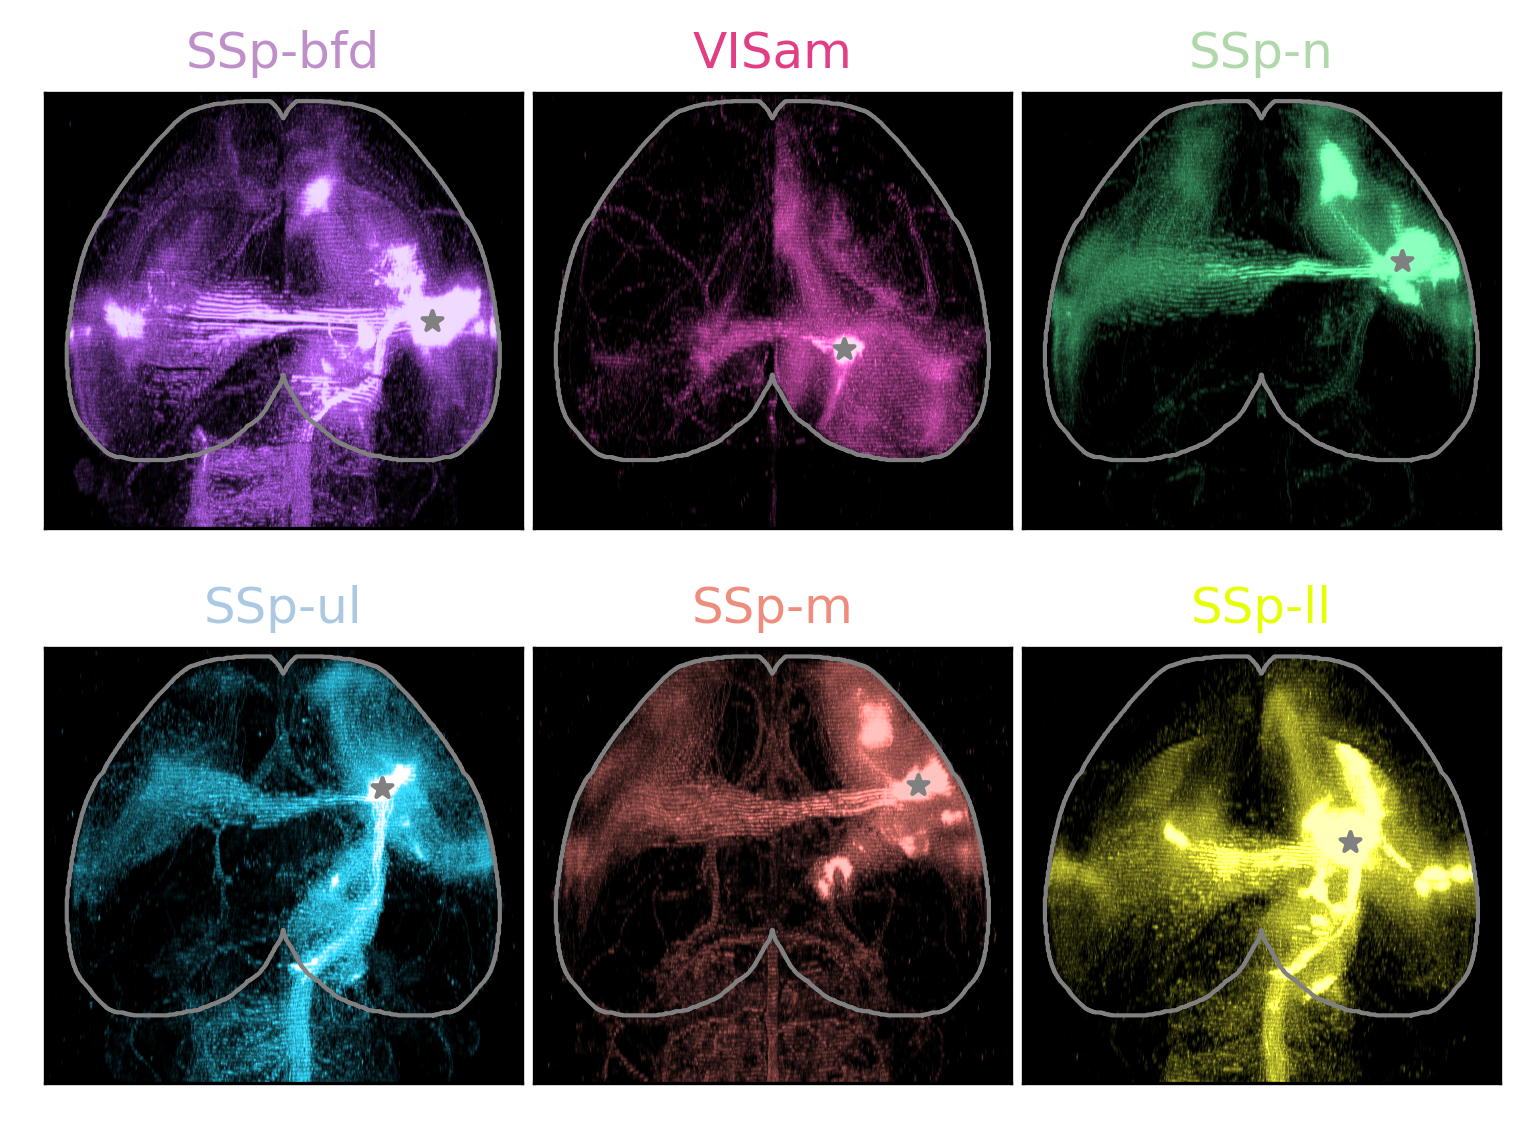

In [27]:
from matplotlib import colors
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)


y_offset = 20;x_offset=20;y_gap=1;x_gap=0;x_width=6

x_start = x_offset
for i_ax in range(3):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+7,x_start:x_start+7])".format(i_ax))
    x_start = x_start+7+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
x_start = x_offset
for i_ax in range(3,6):
    exec("ax{} = fig.add_subplot(gs[y_offset+8:y_offset+15,x_start:x_start+7])".format(i_ax))
    x_start = x_start+7+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))    
    


bdp_short_dict = {'LFP':'SSp-ul','LHP':'SSp-ll','LM':'SSp-m','LW':'SSp-bfd',
                  'LN':'SSp-n','LV':'VISam'}



################################################
for i_key,key in enumerate(dict_experiment_id):
    pd_mip = dict_pd[key].max(axis=1)
    exec("ax{}.imshow(pd_mip*dict_scaling_factor[key],cmap=cmap_dict[key.replace('L','R')],vmin=0,vmax=0.8)".format(i_key))
    exec("ax{}.set_title(bdp_short_dict[key],color=palatte_dict[key])".format(i_key))
    # exec("ax{}.colorbar()".format(i_key))
    for contour in brain_contours:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=1)".format(i_key))
    exec("ax{}.scatter(dict_coord[key][1],dict_coord[key][0],marker='*', s=25, c='gray', zorder=2)".format(i_key))

        
for i_key in range(6):    
    exec("ax{}.set_ylim([1200,160])".format(i_key))
    
plt.savefig('figS4-M2-S1-allen-connectivity-atlas-MIP.svg',format='svg',dpi=300)

In [45]:
dict_pd['brain_mask'] = cortex_mask

In [ ]:
with h5py.File("dict_pd.h5", "w") as h5f:
    for key, array in dict_pd.items():
        h5f.create_dataset(key, data=array)  # no compression
